# 📰 Which News Will Go Viral?
### Predicting Online News Popularity with Machine Learning

An end-to-end classification project that predicts whether a news article will be **highly popular (High)** or **less popular (Low)** based on its content, metadata, and publishing time.

| | |
|---|---|
| **Dataset** | UCI – [Online News Popularity](https://archive.ics.uci.edu/dataset/332/online+news+popularity) (~39,644 Mashable articles, 58 features + `shares`) |
| **Tools** | Python, Pandas, NumPy, Scikit-learn, Matplotlib, Seaborn |
| **Task** | Binary classification: `popular = 1` if `shares` ≥ median, else `0` |
| **Models** | Dummy baseline, Logistic Regression, Random Forest |

## Workflow
EDA → Cleaning → Factor analysis → Train/Test split → Feature selection (Mutual Information) → Random Forest → Evaluation → Logistic Regression → Model comparison → Cross-validation → Model export

## Key results
| Model | Accuracy | ROC AUC |
|---|---|---|
| Baseline (most frequent) | 0.532 | 0.500 |
| Logistic Regression | 0.641 | 0.694 |
| **Random Forest** | **0.665** | **0.729** |

> Random Forest (5-fold CV accuracy: 0.663 ± 0.007) beats the baseline by ~13 percentage points. Reproducibility: `RANDOM_STATE = 42` is used everywhere.

## 1. Setup

In [1]:
import warnings, io, zipfile, urllib.request
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_selection import mutual_info_classif
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, roc_auc_score, RocCurveDisplay)

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

## 2. Load & Inspect the Data

In [2]:
URL = "https://archive.ics.uci.edu/static/public/332/online+news+popularity.zip"

try:
    raw = urllib.request.urlopen(URL, timeout=60).read()
    with zipfile.ZipFile(io.BytesIO(raw)) as z:
        csv_name = [n for n in z.namelist() if n.endswith(".csv")][0]
        df = pd.read_csv(z.open(csv_name))
    print("Loaded from UCI ✅")
except Exception as e:
    # Fallback: use the local copy in data/ (see data/README.md)
    print("Download failed:", e)
    df = pd.read_csv("../data/OnlineNewsPopularity.csv")

Loaded from UCI ✅


In [3]:
df.head(3)

,url,timedelta,n_tokens_title,n_tokens_content,n_unique_tokens,n_non_stop_words,n_non_stop_unique_tokens,num_hrefs,num_self_hrefs,num_imgs,...,min_positive_polarity,max_positive_polarity,avg_negative_polarity,min_negative_polarity,max_negative_polarity,title_subjectivity,title_sentiment_polarity,abs_title_subjectivity,abs_title_sentiment_polarity,shares
0,http://mashable.com/2013/01/07/amazon-instant-...,731.0,12.0,219.0,0.663594,1.0,0.815385,4.0,2.0,1.0,...,0.100000,0.7,-0.350000,-0.600,-0.200000,0.5,-0.1875,0.0,0.1875,593
1,http://mashable.com/2013/01/07/ap-samsung-spon...,731.0,9.0,255.0,0.604743,1.0,0.791946,3.0,1.0,1.0,...,0.033333,0.7,-0.118750,-0.125,-0.100000,0.0,0.0000,0.5,0.0000,711
2,http://mashable.com/2013/01/07/apple-40-billio...,731.0,9.0,211.0,0.575130,1.0,0.663866,3.0,1.0,1.0,...,0.100000,1.0,-0.466667,-0.800,-0.133333,0.0,0.0000,0.5,0.0000,1500


In [4]:
df.columns

Index(['url', ' timedelta', ' n_tokens_title', ' n_tokens_content',
       ' n_unique_tokens', ' n_non_stop_words', ' n_non_stop_unique_tokens',
       ' num_hrefs', ' num_self_hrefs', ' num_imgs', ' num_videos',
       ' average_token_length', ' num_keywords', ' data_channel_is_lifestyle',
       ' data_channel_is_entertainment', ' data_channel_is_bus',
       ' data_channel_is_socmed', ' data_channel_is_tech',
       ' data_channel_is_world', ' kw_min_min', ' kw_max_min', ' kw_avg_min',
       ' kw_min_max', ' kw_max_max', ' kw_avg_max', ' kw_min_avg',
       ' kw_max_avg', ' kw_avg_avg', ' self_reference_min_shares',
       ' self_reference_max_shares', ' self_reference_avg_sharess',
       ' weekday_is_monday', ' weekday_is_tuesday', ' weekday_is_wednesday',
       ' weekday_is_thursday', ' weekday_is_friday', ' weekday_is_saturday',
       ' weekday_is_sunday', ' is_weekend', ' LDA_00', ' LDA_01', ' LDA_02',
       ' LDA_03', ' LDA_04', ' global_subjectivity',
       ' global_sent

The column names contain a hidden leading space (e.g. `' shares'`). The next cells fix the names, inspect the dataset (shape, missing values, duplicates, dtypes), and summarise a few key features.

In [4]:
# Fix column names and display first rows
df.columns = df.columns.str.strip()
df.head()

,url,timedelta,n_tokens_title,n_tokens_content,n_unique_tokens,n_non_stop_words,n_non_stop_unique_tokens,num_hrefs,num_self_hrefs,num_imgs,...,min_positive_polarity,max_positive_polarity,avg_negative_polarity,min_negative_polarity,max_negative_polarity,title_subjectivity,title_sentiment_polarity,abs_title_subjectivity,abs_title_sentiment_polarity,shares
0,http://mashable.com/2013/01/07/amazon-instant-...,731.0,12.0,219.0,0.663594,1.0,0.815385,4.0,2.0,1.0,...,0.100000,0.7,-0.350000,-0.600,-0.200000,0.500000,-0.187500,0.000000,0.187500,593
1,http://mashable.com/2013/01/07/ap-samsung-spon...,731.0,9.0,255.0,0.604743,1.0,0.791946,3.0,1.0,1.0,...,0.033333,0.7,-0.118750,-0.125,-0.100000,0.000000,0.000000,0.500000,0.000000,711
2,http://mashable.com/2013/01/07/apple-40-billio...,731.0,9.0,211.0,0.575130,1.0,0.663866,3.0,1.0,1.0,...,0.100000,1.0,-0.466667,-0.800,-0.133333,0.000000,0.000000,0.500000,0.000000,1500
3,http://mashable.com/2013/01/07/astronaut-notre...,731.0,9.0,531.0,0.503788,1.0,0.665635,9.0,0.0,1.0,...,0.136364,0.8,-0.369697,-0.600,-0.166667,0.000000,0.000000,0.500000,0.000000,1200
4,http://mashable.com/2013/01/07/att-u-verse-apps/,731.0,13.0,1072.0,0.415646,1.0,0.540890,19.0,19.0,20.0,...,0.033333,1.0,-0.220192,-0.500,-0.050000,0.454545,0.136364,0.045455,0.136364,505


In [5]:
# Basic dataset inspection

print("Rows and Columns:", df.shape)

print("Missing Values:", df.isna().sum().sum())

print("Duplicate Rows:", df.duplicated().sum())

df.info()

Rows and Columns: (39644, 61)
Missing Values: 0
Duplicate Rows: 0
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 39644 entries, 0 to 39643
Data columns (total 61 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   url                            39644 non-null  object 
 1   timedelta                      39644 non-null  float64
 2   n_tokens_title                 39644 non-null  float64
 3   n_tokens_content               39644 non-null  float64
 4   n_unique_tokens                39644 non-null  float64
 5   n_non_stop_words               39644 non-null  float64
 6   n_non_stop_unique_tokens       39644 non-null  float64
 7   num_hrefs                      39644 non-null  float64
 8   num_self_hrefs                 39644 non-null  float64
 9   num_imgs                       39644 non-null  float64
 10  num_videos                     39644 non-null  float64
 11  average_token_length           39644 non

In [6]:
# Summary statistics

cols = [
    "n_tokens_title",
    "n_tokens_content",
    "num_hrefs",
    "num_imgs",
    "num_videos",
    "shares"
]

df[cols].describe()

,n_tokens_title,n_tokens_content,num_hrefs,num_imgs,num_videos,shares
count,39644.000000,39644.000000,39644.000000,39644.000000,39644.000000,39644.000000
mean,10.398749,546.514731,10.883690,4.544143,1.249874,3395.380184
std,2.114037,471.107508,11.332017,8.309434,4.107855,11626.950749
min,2.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,9.000000,246.000000,4.000000,1.000000,0.000000,946.000000
50%,10.000000,409.000000,8.000000,1.000000,0.000000,1400.000000
75%,12.000000,716.000000,14.000000,4.000000,1.000000,2800.000000
max,23.000000,8474.000000,304.000000,128.000000,91.000000,843300.000000


### Key takeaways
- **One row = one online news article** (Mashable) with its characteristics and the number of times it was shared (`shares`).
- Features I expected to relate to popularity (hypotheses to be verified by the analysis below):
  - `num_imgs` – more images may attract more attention and sharing.
  - `num_videos` – video is often more engaging than text alone.
  - `n_tokens_content` – article length: detailed articles add value, but very long ones may reduce engagement.
- The data has no missing values and no duplicate rows.

## 3. Explore the Target (`shares`)

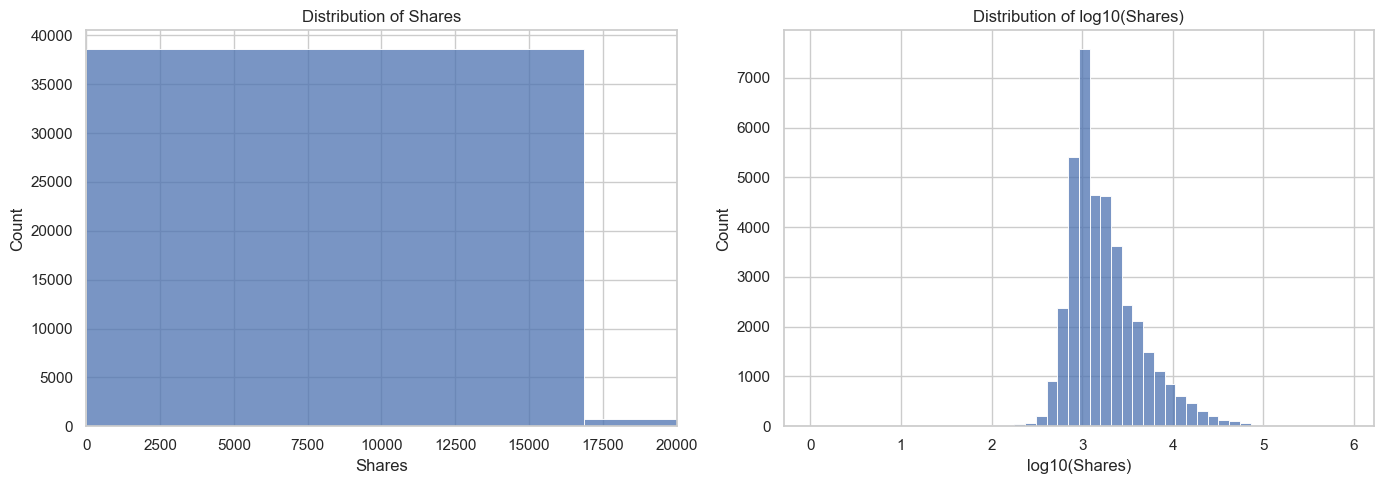

In [7]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Raw Shares
sns.histplot(df["shares"], bins=50, ax=axes[0])
axes[0].set_xlim(0, 20000)
axes[0].set_title("Distribution of Shares")
axes[0].set_xlabel("Shares")

# Log10 Shares
sns.histplot(np.log10(df["shares"]), bins=50, ax=axes[1])
axes[1].set_title("Distribution of log10(Shares)")
axes[1].set_xlabel("log10(Shares)")

plt.tight_layout()
plt.show()

In [8]:
df["shares"].describe()

count     39644.000000
mean       3395.380184
std       11626.950749
min           1.000000
25%         946.000000
50%        1400.000000
75%        2800.000000
max      843300.000000
Name: shares, dtype: float64

### Key takeaways
- The raw distribution is **strongly right-skewed**: most articles have few shares, while a handful go extremely viral (max ≈ 843K vs. median 1,400).
- The **log scale** compresses outliers and reveals a much more symmetric shape, making the data easier to analyse.
- The **mean (3,395) is far above the median (1,400)**, which confirms the skew and the presence of outliers → the median is a more robust measure of "typical" popularity.

## 4. Cleaning & Defining the Target
- Drop `url` and `timedelta` (non-predictive).
- Remove invalid rows: articles with **0 words** and rows where `n_unique_tokens > 1` (a rate cannot exceed 1).
- Create the binary target `popular` = 1 if `shares` ≥ median, else 0.

In [9]:
# Drop unnecessary columns

df.drop(columns=["url", "timedelta"], inplace=True)

In [10]:
# Remove invalid rows

before = len(df)

df = df[
    (df["n_tokens_content"] > 0) &
    (df["n_unique_tokens"] <= 1)
].copy()

removed = before - len(df)

print("Rows removed:", removed)
print("Rows remaining:", len(df))

Rows removed: 1182
Rows remaining: 38462


In [11]:
# Create target variable

median_shares = df["shares"].median()

df["popular"] = (
    df["shares"] >= median_shares
).astype(int)

print(df["popular"].value_counts(normalize=True))

popular
1    0.532032
0    0.467968
Name: proportion, dtype: float64


### Key takeaways
- **Why the median?** It produces balanced classes (≈53% / 47%), so accuracy remains a meaningful metric. A top-10% threshold would create a heavily imbalanced dataset and require different metrics (precision/recall, PR-AUC) and techniques.
- **Why drop `timedelta` and `url`?** `timedelta` (days between publication and data collection) encodes time information not available when a new article is published, and `url` is only an identifier with no predictive value.

## 5. What Influences Popularity?
- **Correlation:** the 8 most negative and 8 most positive features vs. `popular`.
- **Channel:** share of popular articles per `data_channel_is_*` flag.
- **Weekday:** share of popular articles per `weekday_is_*` flag.
- **Images, videos and links:** share of popular articles per bucket.

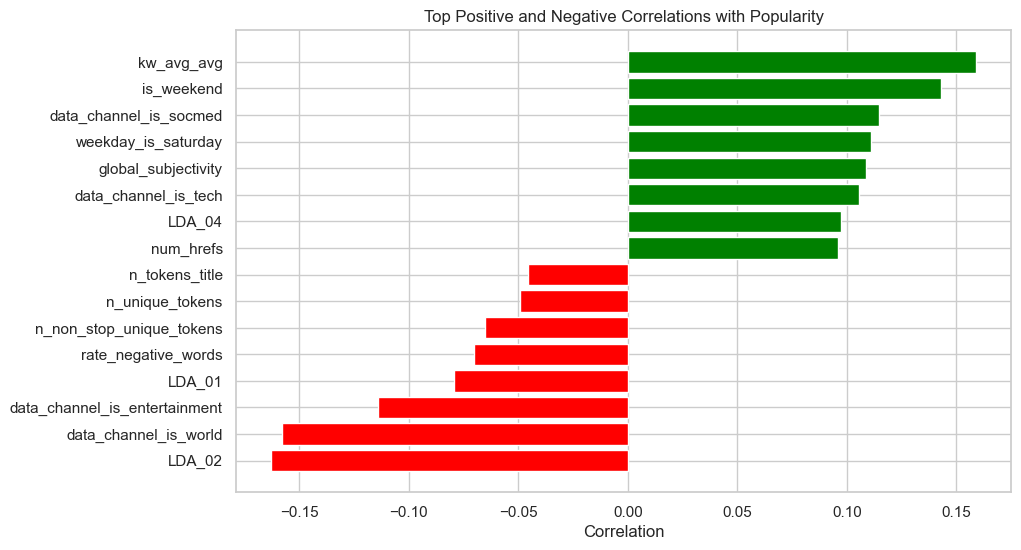

In [12]:
# Correlation with popularity
features = [c for c in df.columns if c not in ["shares", "popular"]]

corr = df[features].corrwith(df["popular"]).sort_values()

top_corr = pd.concat([corr.head(8), corr.tail(8)])

colors = ["red" if x < 0 else "green" for x in top_corr]

plt.figure(figsize=(10, 6))
plt.barh(top_corr.index, top_corr.values, color=colors)
plt.title("Top Positive and Negative Correlations with Popularity")
plt.xlabel("Correlation")
plt.show()

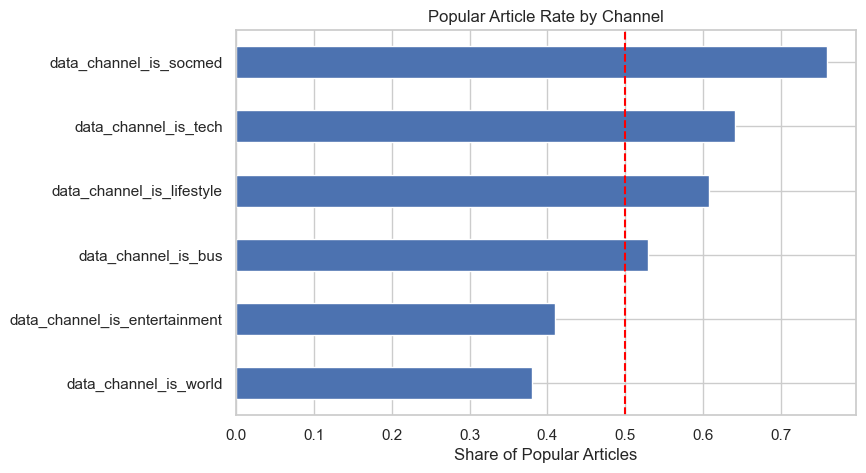

In [13]:
# Popularity by channel
channel_cols = [c for c in df.columns if c.startswith("data_channel_is_")]

channel_pop = {
    col: df[df[col] == 1]["popular"].mean()
    for col in channel_cols
}

channel_pop = pd.Series(channel_pop).sort_values()

plt.figure(figsize=(8, 5))
channel_pop.plot(kind="barh")
plt.axvline(0.5, color="red", linestyle="--")
plt.title("Popular Article Rate by Channel")
plt.xlabel("Share of Popular Articles")
plt.show()

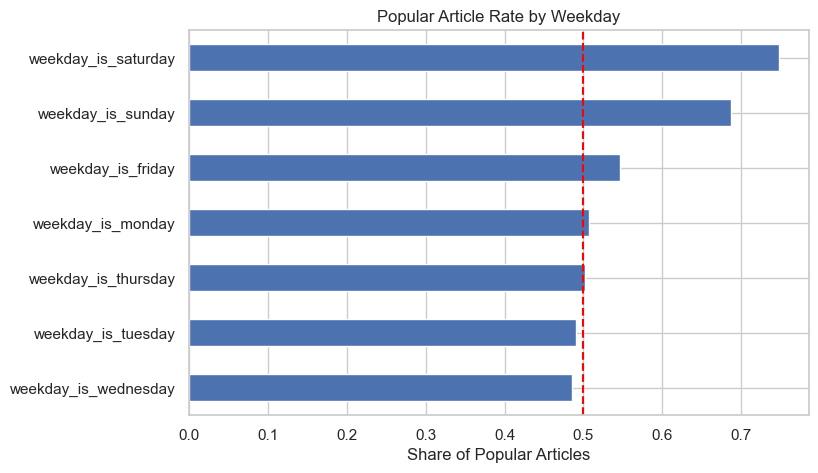

In [14]:
# Popularity by weekday

weekday_cols = [c for c in df.columns if c.startswith("weekday_is_")]

weekday_pop = {
    col: df[df[col] == 1]["popular"].mean()
    for col in weekday_cols
}

weekday_pop = pd.Series(weekday_pop).sort_values()

plt.figure(figsize=(8, 5))
weekday_pop.plot(kind="barh")
plt.axvline(0.5, color="red", linestyle="--")
plt.title("Popular Article Rate by Weekday")
plt.xlabel("Share of Popular Articles")
plt.show()

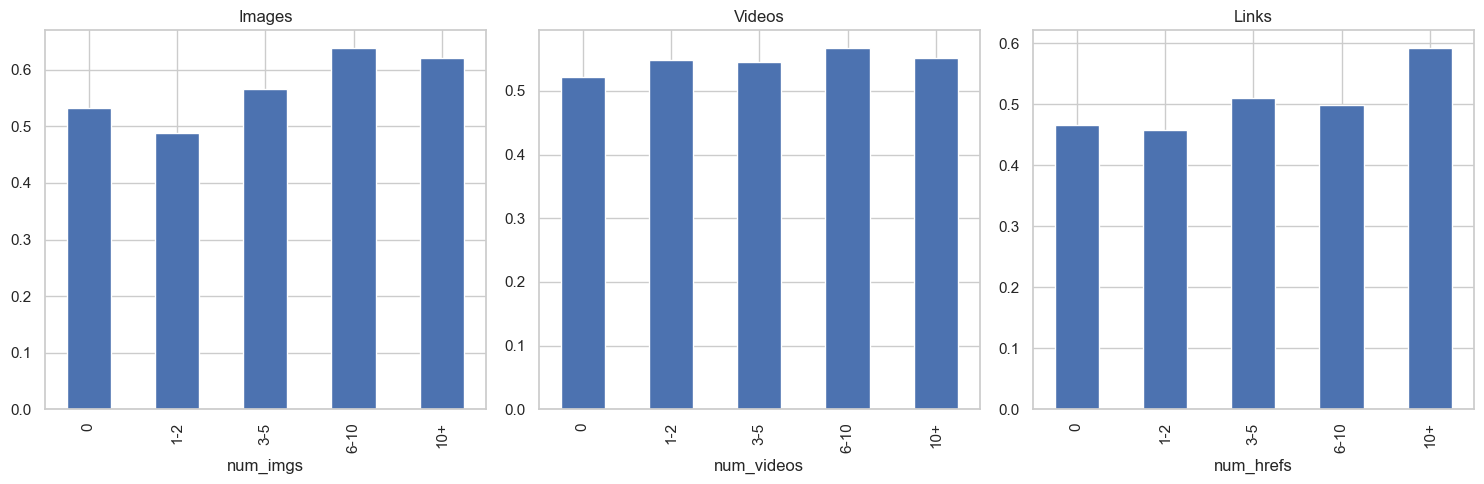

In [15]:
# Images / videos / links
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# Images
img_bins = pd.cut(
    df["num_imgs"],
    bins=[-1, 0, 2, 5, 10, np.inf],
    labels=["0", "1-2", "3-5", "6-10", "10+"])

df.groupby(img_bins)["popular"].mean().plot(
    kind="bar",
    ax=axes[0])

axes[0].set_title("Images")

# Videos
video_bins = pd.cut(
    df["num_videos"],
    bins=[-1, 0, 2, 5, 10, np.inf],
    labels=["0", "1-2", "3-5", "6-10", "10+"])

df.groupby(video_bins)["popular"].mean().plot(
    kind="bar",
    ax=axes[1])

axes[1].set_title("Videos")

# Links
href_bins = pd.cut(
    df["num_hrefs"],
    bins=[-1, 0, 2, 5, 10, np.inf],
    labels=["0", "1-2", "3-5", "6-10", "10+"])

df.groupby(href_bins)["popular"].mean().plot(
    kind="bar",
    ax=axes[2])

axes[2].set_title("Links")

plt.tight_layout()
plt.show()

### Key takeaways
- Some features show clearly stronger correlations with popularity than others (e.g. keyword-based and topic (LDA) features).
- Popularity differs across **channels** and **weekdays**.
- Articles with more **images** or **links** tend to have a higher share of popular articles.
- **Correlation ≠ causation:** a third factor (e.g. topic or article importance) may drive both the number of images and the popularity, so we cannot conclude that adding images *causes* more shares.

## 6. Train / Test Split
80% train / 20% test, **stratified** on the target, `random_state=42`.

In [16]:
from sklearn.model_selection import train_test_split

# Features (everything except the target and its source column)
features_all = [
    col for col in df.columns
    if col not in ["shares", "popular"]
]

# Split
X = df[features_all]
y = df["popular"]

RANDOM_STATE = 42

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=RANDOM_STATE
)

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

X_train: (30769, 58)
X_test : (7693, 58)
y_train: (30769,)
y_test : (7693,)


> **Why split before feature selection?** To prevent **data leakage** — using information from the test set during training or selection. Leakage makes the model look more accurate than it really is and gives overly optimistic results.

## 7. Feature Selection (Mutual Information)
Mutual Information is computed on the **training set only**, then the top **K = 25** features are kept.

LDA_02                       0.035401
kw_max_avg                   0.032932
LDA_04                       0.028587
LDA_00                       0.027778
kw_avg_avg                   0.025023
LDA_01                       0.024131
self_reference_max_shares    0.023249
LDA_03                       0.022904
kw_max_min                   0.021579
self_reference_min_shares    0.021279
dtype: float64


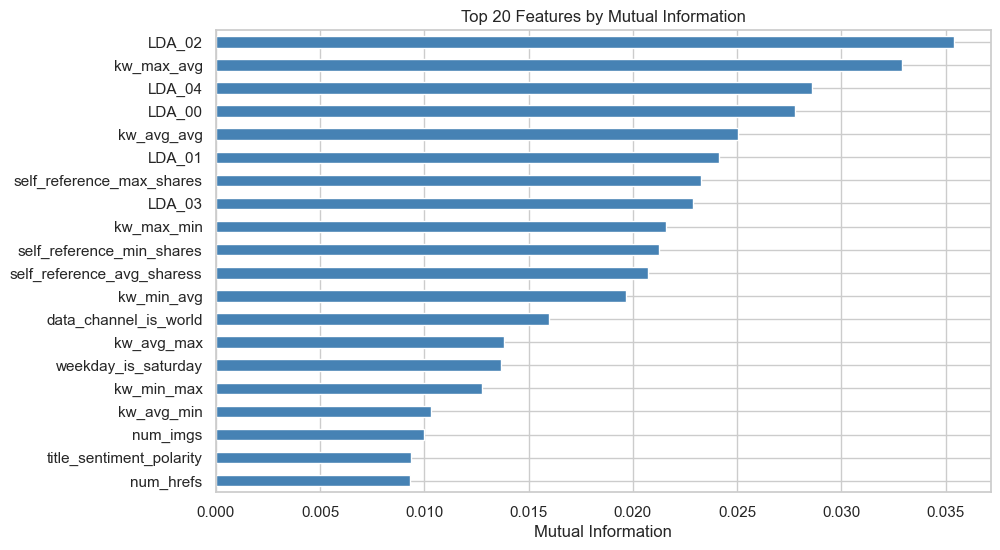

Selected Features: 25
X_train_sel: (30769, 25)
X_test_sel : (7693, 25)


In [17]:
K = 25
from sklearn.feature_selection import mutual_info_classif

# Mutual Information

mi = mutual_info_classif(
    X_train,
    y_train,
    random_state=RANDOM_STATE)

mi = pd.Series(
    mi,
    index=X_train.columns
).sort_values(ascending=False)

print(mi.head(10))

# Top 20 Features

plt.figure(figsize=(10, 6))

mi.head(20).sort_values().plot(
    kind="barh",
    color="steelblue")

plt.title("Top 20 Features by Mutual Information")
plt.xlabel("Mutual Information")
plt.show()

# Top K = 25 Features

K = 25

selected = mi.head(K).index.tolist()

X_train_sel = X_train[selected]
X_test_sel = X_test[selected]

print("Selected Features:", len(selected))
print("X_train_sel:", X_train_sel.shape)
print("X_test_sel :", X_test_sel.shape)

### Key takeaways
- **Mutual Information** measures how much knowing a feature reduces uncertainty about the target. Unlike correlation, it can capture **non-linear** relationships.
- Top 5 features: `LDA_02`, `kw_max_avg`, `LDA_04`, `LDA_00`, `kw_avg_avg` — topic (LDA) and keyword-performance features dominate.
- These mostly agree with the findings in Section 5, where keyword and topic features also showed the strongest relationships with popularity.

## 8. Baseline & Random Forest
- **Baseline:** `DummyClassifier(strategy="most_frequent")` as a benchmark.
- **Random Forest:** 300 trees, `max_depth=15`, `min_samples_leaf=5`, trained on the 25 selected features.

In [18]:
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

# Baseline Model
baseline = DummyClassifier(
    strategy="most_frequent")

baseline.fit(X_train_sel, y_train)

y_pred_base = baseline.predict(X_test_sel)

baseline_acc = accuracy_score(
    y_test,
    y_pred_base)

print("Baseline Accuracy:", baseline_acc)

# Random Forest

rf = RandomForestClassifier(
    n_estimators=300,
    max_depth=15,
    min_samples_leaf=5,
    n_jobs=-1,
    random_state=RANDOM_STATE)

rf.fit(X_train_sel, y_train)

Baseline Accuracy: 0.5320421162095411


,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",300
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",15
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",5
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric(y

> **Why a baseline?** It gives a simple benchmark: any real model must beat it to be worth using. A **Random Forest** is a group of decision trees that each make a prediction; the final prediction is the majority vote of all trees.

## 9. Evaluate the Random Forest
Accuracy, ROC AUC, classification report, confusion matrix, ROC curve, and feature importances.

Accuracy: 0.6650201481866632
ROC AUC: 0.7286597035589217
              precision    recall  f1-score   support

         Low       0.66      0.59      0.62      3600
        High       0.67      0.73      0.70      4093

    accuracy                           0.67      7693
   macro avg       0.66      0.66      0.66      7693
weighted avg       0.66      0.67      0.66      7693



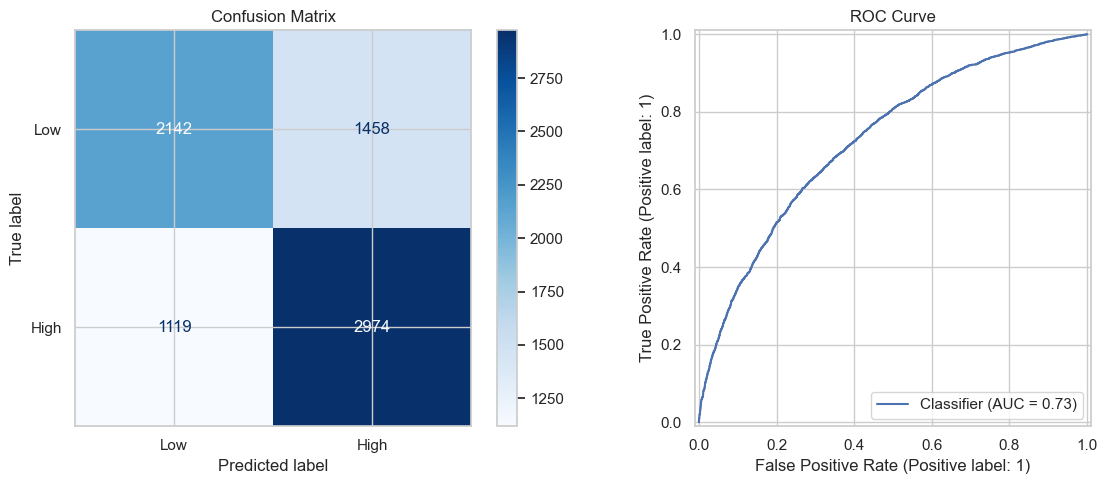

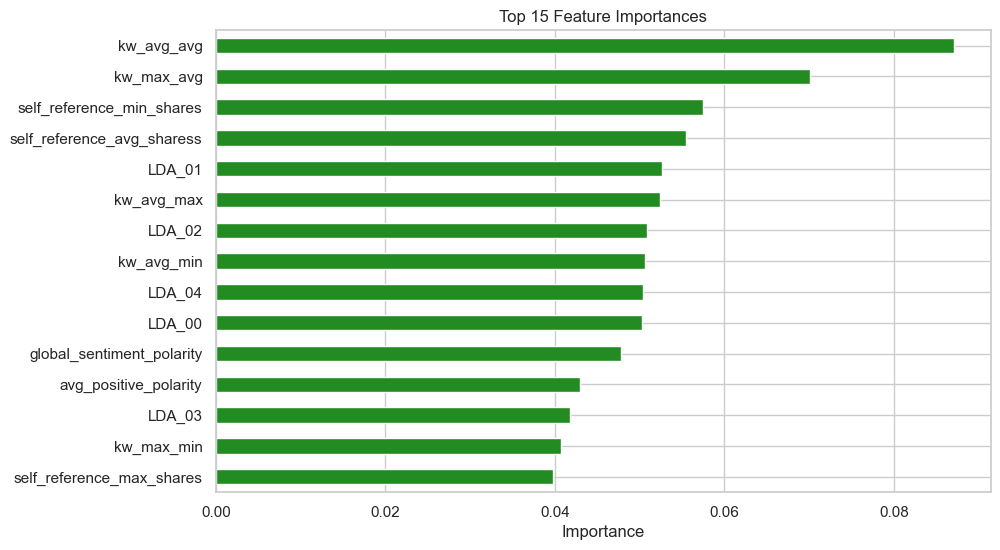

In [19]:
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    RocCurveDisplay)

# Predictions
# Predictions
y_pred = rf.predict(X_test_sel)
y_proba = rf.predict_proba(X_test_sel)[:, 1]

# Metrics

print("Accuracy:", accuracy_score(y_test, y_pred))
print("ROC AUC:", roc_auc_score(y_test, y_proba))
print(
    classification_report(
        y_test,
        y_pred,
        target_names=["Low", "High"]))

# Confusion Matrix & ROC Curve

fig, ax = plt.subplots(1, 2, figsize=(12, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["Low", "High"],
    cmap="Blues",
    ax=ax[0])

ax[0].set_title("Confusion Matrix")

RocCurveDisplay.from_predictions(
    y_test,
    y_proba,
    ax=ax[1])
ax[1].set_title("ROC Curve")
plt.tight_layout()
plt.show()

# Top 15 Feature Importances

importance = pd.Series(
    rf.feature_importances_,
    index=selected
).sort_values(ascending=False)
plt.figure(figsize=(10, 6))

importance.head(15).sort_values().plot(
    kind="barh",
    color="forestgreen")
plt.title("Top 15 Feature Importances")
plt.xlabel("Importance")
plt.show()

### Key takeaways
**Confusion matrix**
- **True Positive:** a popular article correctly predicted as popular.
- **True Negative:** an unpopular article correctly predicted as unpopular.
- **False Positive:** an unpopular article predicted as popular.
- **False Negative:** a popular article predicted as unpopular.

**Why only ~66.5% accuracy?** Many drivers of popularity are not in the data: the actual article text, headline quality, social-media activity, timing relative to news events, and author/brand reach.

**Importance vs. Section 7:** Some top features overlap, but *important* ≠ *causes popularity* — feature importance shows association and predictive usefulness, not causation.

## 10. Logistic Regression & Model Comparison
A `StandardScaler` + `LogisticRegression` pipeline is trained on the same selected features, then compared against the baseline and Random Forest.

In [20]:
logreg = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        max_iter=1000,
        random_state=RANDOM_STATE
    )
)

logreg.fit(X_train_sel, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('standardscaler', ...), ('logisticregression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some 

Accuracy: 0.6414922656960873
ROC AUC: 0.693854955615278
              precision    recall  f1-score   support

         Low       0.62      0.59      0.60      3600
        High       0.65      0.69      0.67      4093

    accuracy                           0.64      7693
   macro avg       0.64      0.64      0.64      7693
weighted avg       0.64      0.64      0.64      7693



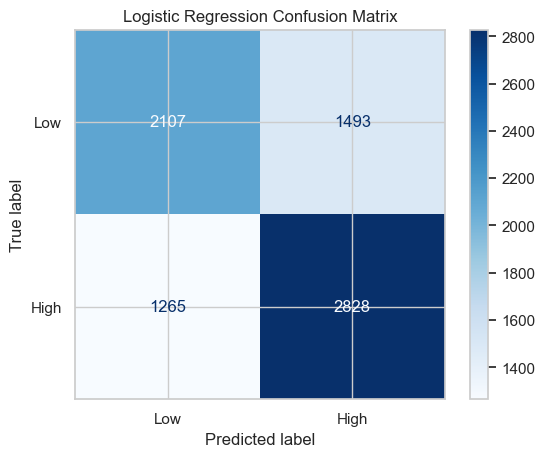

In [21]:
lr_pred = logreg.predict(X_test_sel)
lr_proba = logreg.predict_proba(X_test_sel)[:, 1]

print("Accuracy:", accuracy_score(y_test, lr_pred))
print("ROC AUC:", roc_auc_score(y_test, lr_proba))
print(
    classification_report(
        y_test,
        lr_pred,
        target_names=["Low", "High"]))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    lr_pred,
    display_labels=["Low", "High"],
    cmap="Blues")
plt.title("Logistic Regression Confusion Matrix")
plt.show()

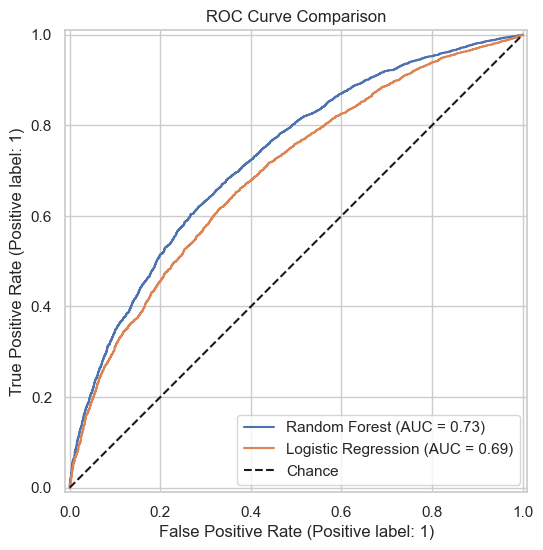

In [22]:
# ROC curves of both models (same axes)
fig, ax = plt.subplots(figsize=(8, 6))

RocCurveDisplay.from_predictions(
    y_test, y_proba, name="Random Forest", ax=ax)

RocCurveDisplay.from_predictions(
    y_test, lr_proba, name="Logistic Regression", ax=ax)

ax.plot([0, 1], [0, 1], "k--", label="Chance")
ax.set_title("ROC Curve Comparison")
ax.legend()
plt.show()

In [23]:
# Model comparison table
comparison = pd.DataFrame({
    "Model": [
        "Baseline",
        "Logistic Regression",
        "Random Forest"
    ],
    "Accuracy": [
        accuracy_score(y_test, y_pred_base),
        accuracy_score(y_test, lr_pred),
        accuracy_score(y_test, y_pred)
    ],
    "Precision (High)": [
        precision_score(
            y_test,
            y_pred_base,
            zero_division=0
        ),
        precision_score(y_test, lr_pred),
        precision_score(y_test, y_pred)
    ],
    "Recall (High)": [
        recall_score(
            y_test,
            y_pred_base,
            zero_division=0
        ),
        recall_score(y_test, lr_pred),
        recall_score(y_test, y_pred)
    ],
    "F1 (High)": [
        f1_score(
            y_test,
            y_pred_base,
            zero_division=0
        ),
        f1_score(y_test, lr_pred),
        f1_score(y_test, y_pred)
    ],
    "ROC AUC": [
        0.50,
        roc_auc_score(y_test, lr_proba),
        roc_auc_score(y_test, y_proba)
    ]
})

comparison

,Model,Accuracy,Precision (High),Recall (High),F1 (High),ROC AUC
0,Baseline,0.532042,0.532042,1.000000,0.694553,0.500000
1,Logistic Regression,0.641492,0.654478,0.690936,0.672213,0.693855
2,Random Forest,0.665020,0.671029,0.726606,0.697713,0.728660


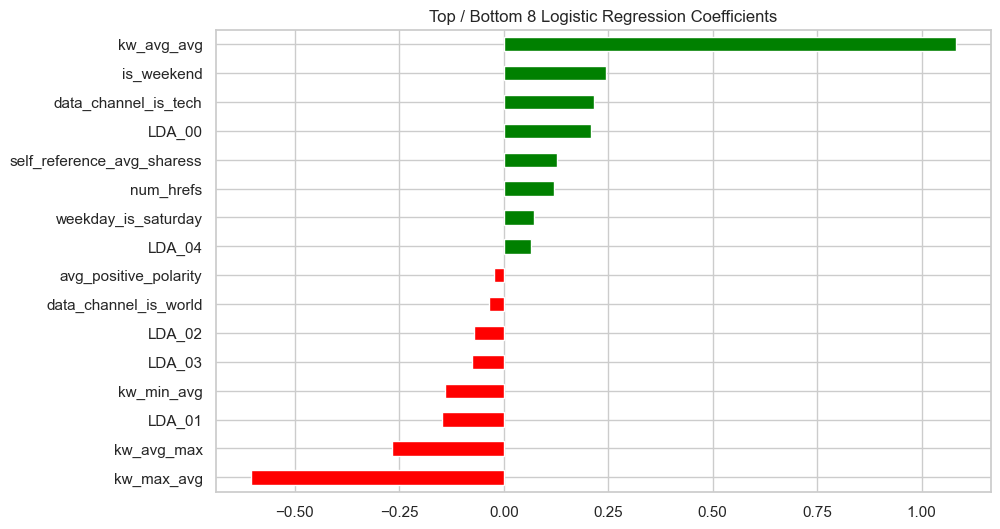

In [24]:
# Coefficients: top / bottom 8
coef = pd.Series(
    logreg[-1].coef_[0],
    index=selected
).sort_values()

coef_plot = pd.concat([
    coef.head(8),
    coef.tail(8)
])

plt.figure(figsize=(10,6))

colors = [
    "red" if x < 0 else "green"
    for x in coef_plot
]

coef_plot.plot(
    kind="barh",
    color=colors
)

plt.title("Top / Bottom 8 Logistic Regression Coefficients")
plt.show()

In [25]:
# Odds Ratios

odds_ratios = np.exp(coef)

print("Top 10 Odds Ratios")

display(
    odds_ratios.sort_values(
        ascending=False
    ).head(10)
)

Top 10 Odds Ratios


kw_avg_avg                    2.949396
is_weekend                    1.278650
data_channel_is_tech          1.240092
LDA_00                        1.233115
self_reference_avg_sharess    1.136715
num_hrefs                     1.128212
weekday_is_saturday           1.074755
LDA_04                        1.067556
title_sentiment_polarity      1.042427
global_sentiment_polarity     1.031946
dtype: float64

### Key takeaways
- **Why scaling?** Logistic Regression is sensitive to feature scales (it optimises coefficients with gradient-based methods and relies on comparable magnitudes), while Random Forest splits on thresholds and is scale-invariant.
- **Which model is better?** Random Forest: accuracy **0.665 vs. 0.641** (+2.4 pp) and ROC AUC **0.729 vs. 0.694** (+0.035). The gap is modest but consistent across metrics, and it's larger than the fold-to-fold standard deviation (≈0.007).
- **Odds ratios:** `kw_avg_avg` has an odds ratio of ≈ 2.95 → a one-standard-deviation increase in the average keyword performance multiplies the odds of being popular by about 2.95, holding the other features constant.
- **Deployment choice:** Random Forest — better performance and it captures non-linear interactions. Logistic Regression remains a good option when interpretability (odds ratios) matters more than raw performance.

## 11. Model Stability (5-Fold Cross-Validation)
Is a single test score trustworthy? Cross-validation on the training set checks how stable the Random Forest is.

In [26]:
from sklearn.model_selection import cross_val_score

cv_scores = cross_val_score(
    rf,
    X_train_sel,
    y_train,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)

print("CV Scores:", cv_scores)

print(
    "Mean Accuracy: {:.4f}".format(
        cv_scores.mean()
    )
)

print(
    "Std Accuracy: {:.4f}".format(
        cv_scores.std()
    )
)

CV Scores: [0.65112122 0.66753331 0.66525837 0.66314592 0.66991711]
Mean Accuracy: 0.6634
Std Accuracy: 0.0065


**Result:** mean accuracy **0.6634 ± 0.0065** across 5 folds.

The small standard deviation shows the model performs consistently across folds, and the CV mean is very close to the held-out test accuracy (0.665) — so the single test score is trustworthy.

## 12. Conclusions & Limitations
- **Hardest part:** selecting the best features among 58 correlated ones.
- **Surprise:** how skewed the `shares` distribution is — a tiny fraction of articles captures most of the shares.
- **Model:** Random Forest reaches ~66.5% accuracy and 0.73 ROC AUC, clearly above the 53% baseline, but still misses important factors.
- **How to improve:** add article text (TF-IDF / embeddings), headline features, social-media signals, and author/brand data; try gradient boosting and hyperparameter tuning.
- **Ethical concern:** optimising for predicted virality may encourage **clickbait** over quality journalism.

## 13. Save the Model
Export the trained Random Forest and the selected feature list for later use (e.g. an API).

In [27]:
import joblib

joblib.dump(rf, "news_popularity_rf.pkl")

print("Model saved successfully")

Model saved successfully


In [28]:
joblib.dump(selected, "selected_features.pkl")
print("Selected features saved successfully")

Selected features saved successfully


Load them later:

In [ ]:
import joblib

rf = joblib.load("news_popularity_rf.pkl")
selected = joblib.load("selected_features.pkl")